# Análise exploratória: Emissões de GEE da cidade do Rio de Janeiro (2012 a 2024)

**Autores:** Cassiano Siqueira e André de Moraes · **Disciplina:** Linguagem de Programação (Análise e Visualização de Dados com Python) · Bacharelado em Sistemas de Informação, Unilasalle RJ

**Fonte:** Data.Rio / IPP, tabela 3696 (inventário por escopo, metodologia GPC). Dados processados por `src/etl.py`.

**Perguntas de pesquisa**
- **RQ1.** Como o volume total de emissões (t CO₂e) evoluiu entre 2012 e 2024?
- **RQ2.** Quais setores são os principais ofensores de emissões diretas (Escopo 1)?
- **RQ3.** Qual a participação dos subsetores Residencial e Comercial nas emissões indiretas por energia (Escopo 2)?

In [1]:
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))  # permite importar o pacote src
from src import etl, metricas as m

pd.options.display.float_format = "{:,.1f}".format
if not m.CSV.exists():  # gera o dado processado se ainda não existir
    etl.executar()
df = m.carregar()
df.head()

,ano,macrossetor,setor,nivel,escopo,emissao_tCO2e,qualidade_dado
0,2012,NaN,Compostagem (fora do total),item_informativo,Escopo 1,0.0,zero
1,2012,NaN,Compostagem (fora do total),item_informativo,Escopo 2,NaN,nao_disponivel
2,2012,NaN,Compostagem (fora do total),item_informativo,Escopo 3,NaN,nao_disponivel
3,2012,NaN,Compostagem (fora do total),item_informativo,Total,0.0,zero
4,2012,NaN,Geração de energia elétrica para o Sistema Interligado Nacional (fora do total),item_informativo,Escopo 1,"2,344,414.6",valor


## 1. Estrutura e qualidade dos dados

A tabela é **hierárquica**: cada macrossetor (GPC) tem subsetores, e há uma linha `TOTAL` oficial. A coluna `nivel` identifica cada tipo de linha e `qualidade_dado` preserva a diferença entre **zero**, **valor** e **dado não disponível/não estimado** (que *não* são convertidos em zero).

In [2]:
print(f"Linhas: {len(df)} | Anos: {df.ano.min()} a {df.ano.max()} | Setores distintos: {df.setor.nunique()}")
print("\nLinhas por nível (÷ 52 colunas ano×escopo):")
print((df.nivel.value_counts() / df.groupby(["ano", "escopo"]).ngroups).to_string())
print("\nQualidade dos dados:")
print(df.qualidade_dado.value_counts().to_string())

Linhas: 2028 | Anos: 2012 a 2024 | Setores distintos: 39

Linhas por nível (÷ 52 colunas ano×escopo):
nivel
subsetor           31.0
macrossetor         5.0
item_informativo    2.0
total               1.0

Qualidade dos dados:
qualidade_dado
valor             1334
nao_disponivel     557
zero               132
nao_estimado         5


### Armadilha da hierarquia: somar tudo duplica as emissões

Como os subsetores já estão contidos nos macrossetores, somar as duas camadas conta cada tonelada duas vezes. O total correto é a linha `TOTAL` oficial.

In [3]:
oficial = m.total_por_ano(df)
ingenua = df[df.nivel.isin(["macrossetor", "subsetor"]) & (df.escopo == "Total")].groupby("ano")["emissao_tCO2e"].sum()
comparacao = pd.DataFrame({"TOTAL oficial": oficial, "Soma macro+sub": ingenua, "razão": ingenua / oficial})
print(comparacao.loc[[2012, 2020, 2024]].to_string(float_format=lambda v: f"{v:,.2f}" if v < 10 else f"{v:,.0f}"))

      TOTAL oficial  Soma macro+sub  razão
ano                                       
2012     22,272,001      44,544,003   2.00
2020     17,359,267      34,718,534   2.00
2024     19,842,452      39,684,903   2.00


## 2. RQ1: Evolução do total de emissões

Média anual: 21.20 Mt | Desvio-padrão: 1.85 Mt | CV: 8.7%
Máximo: 2014 (24.17 Mt) | Mínimo: 2020 (17.36 Mt)
Variação 2012→2024: -10.9% | Pico (2014)→2024: -17.9%

Variação anual (%):
ano
2013     2.4
2014     6.0
2015    -3.3
2016    -5.4
2017    -0.6
2018    -4.2
2019    -0.4
2020   -17.1
2021    18.7
2022    -6.3
2023     2.6
2024     0.2

Participação dos escopos (%):
escopo  Escopo 1  Escopo 2  Escopo 3
ano                                 
2012        73.2       6.1      20.8
2014        66.4      12.2      21.3
2020        75.7       6.8      17.5
2024        74.0       5.8      20.3


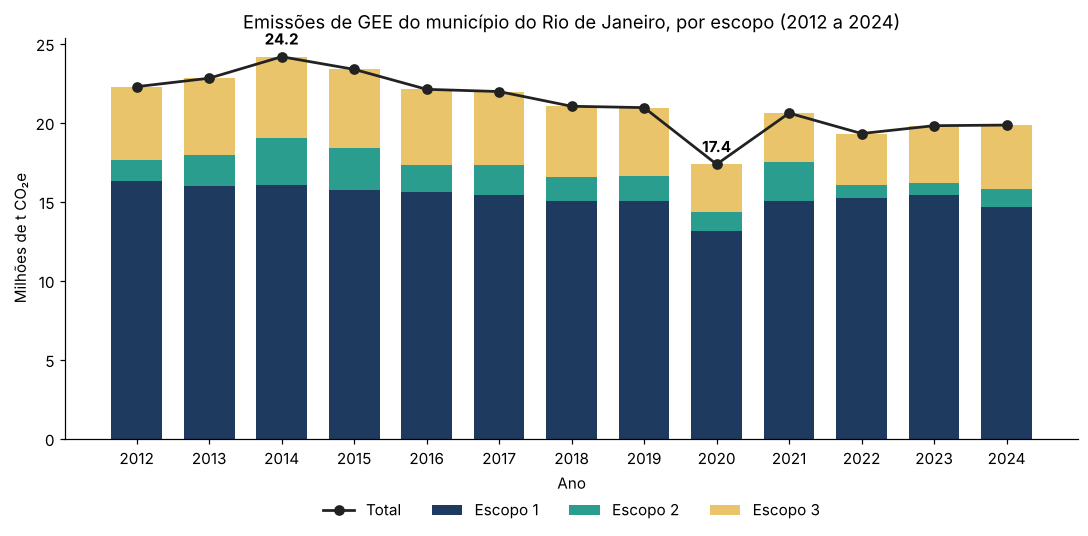

In [4]:
total = m.total_por_ano(df)
r = m.resumo_descritivo(total)
print(f"Média anual: {r['media']/1e6:.2f} Mt | Desvio-padrão: {r['desvio_padrao']/1e6:.2f} Mt | CV: {r['coef_variacao_pct']:.1f}%")
print(f"Máximo: {r['maximo'][0]} ({r['maximo'][1]/1e6:.2f} Mt) | Mínimo: {r['minimo'][0]} ({r['minimo'][1]/1e6:.2f} Mt)")
print(f"Variação 2012→2024: {r['var_primeiro_ultimo_pct']:.1f}% | Pico (2014)→2024: {100*(total[2024]/total[2014]-1):.1f}%")
print("\nVariação anual (%):")
print((total.pct_change() * 100).round(1).dropna().to_string())
esc = m.escopos_por_ano(df)
print("\nParticipação dos escopos (%):")
print((esc.div(esc.sum(axis=1), axis=0) * 100).round(1).loc[[2012, 2014, 2020, 2024]].to_string())
m.fig_rq1(df);

## 3. RQ2: Principais ofensores de emissões diretas (Escopo 1)

Participação dos macrossetores no Escopo 1 (%):
ano                                      2012  2020  2024
setor                                                    
Agropecuária, Floresta e Uso do Solo      0.1   0.3   0.3
Energia Estacionária                     45.8  52.1  52.9
Processos Industriais e Uso de Produtos  15.0  16.9  12.2
Resíduos                                  5.8   4.1   3.5
Transportes                              33.3  26.6  31.1

Concentração em 2024 (dois maiores macrossetores): 84.0% do Escopo 1

Cinco maiores subsetores em 2024:
                                setor                             macrossetor  emissao_tCO2e  pct_escopo1
Indústrias de manufatura e construção                    Energia Estacionária      6,661,113         45.4
                           Rodoviário                             Transportes      4,465,254         30.4
              Produção de ferro e aço Processos Industriais e Uso de Produtos      1,639,966         11.2
                 

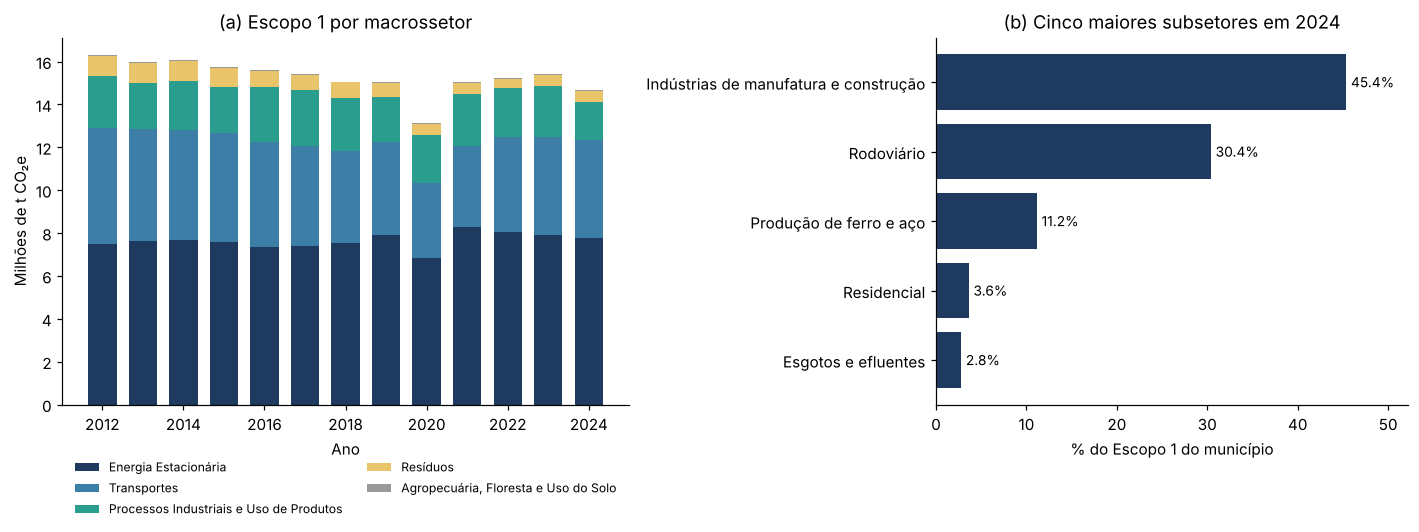

In [5]:
mac = m.escopo1_por_macrossetor(df)
part = mac.div(mac.sum(axis=1), axis=0) * 100
print("Participação dos macrossetores no Escopo 1 (%):")
print(part.round(1).loc[[2012, 2020, 2024]].T.to_string())
print(f"\nConcentração em 2024 (dois maiores macrossetores): {m.concentracao(part.loc[2024], 2):.1f}% do Escopo 1")
print("\nCinco maiores subsetores em 2024:")
print(m.top_subsetores_escopo1(df, ano=2024).to_string(index=False, float_format=lambda v: f"{v:,.1f}" if v < 100 else f"{v:,.0f}"))
m.fig_rq2(df);

## 4. RQ3: Residencial e Comercial no Escopo 2

Participação no Escopo 2 do município (%):
setor  Residencial (%)  Comercial (%)
ano                                  
2012              27.5           30.7
2014              28.2           32.0
2020              29.9           29.4
2024              26.9           28.6

Residencial + Comercial: 55.5% a 62.6% do Escopo 2 ao longo da série
Residencial: CV = 40.7% | pico 2014 | variação 2012→2024 = -17.2%
Comercial: CV = 42.6% | pico 2014 | variação 2012→2024 = -21.2%

Correlação Residencial × Comercial (2012 a 2024): 0.992


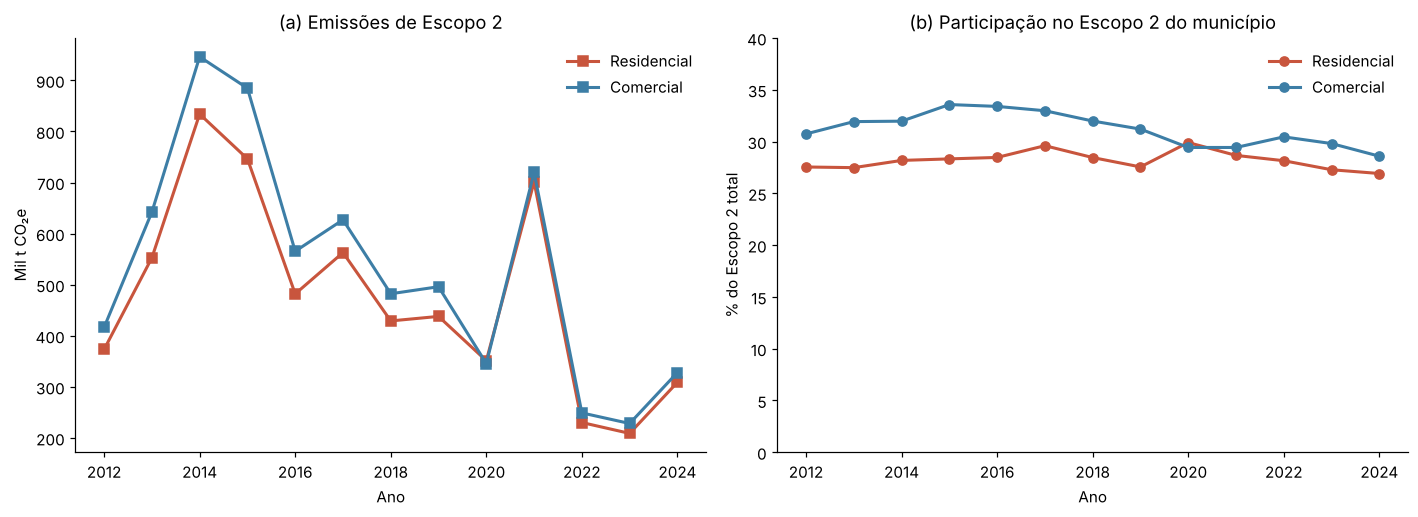

In [6]:
sub = m.escopo2_subsetores(df)
part2 = m.participacao_escopo2(df)
print("Participação no Escopo 2 do município (%):")
print(part2.round(1).loc[[2012, 2014, 2020, 2024]].to_string())
print(f"\nResidencial + Comercial: {part2.sum(axis=1).min():.1f}% a {part2.sum(axis=1).max():.1f}% do Escopo 2 ao longo da série")
for s in ("Residencial", "Comercial"):
    r = m.resumo_descritivo(sub[s])
    print(f"{s}: CV = {r['coef_variacao_pct']:.1f}% | pico {r['maximo'][0]} | variação 2012→2024 = {r['var_primeiro_ultimo_pct']:.1f}%")
print(f"\nCorrelação Residencial × Comercial (2012 a 2024): {sub['Residencial'].corr(sub['Comercial']):.3f}")
m.fig_rq3(df);

## 5. Exportação para o artigo web

In [7]:
dados = m.exportar_dados_web(df)
print("Arquivos gerados em docs/assets/:", ", ".join(sorted(p.name for p in m.ASSETS.iterdir())))

Arquivos gerados em docs/assets/: dados_graficos.js, dados_graficos.json, rq1_evolucao_temporal.png, rq2_ofensores_escopo1.png, rq3_matriz_energetica.png


## 6. Síntese

- **RQ1:** o total caiu de 22,3 Mt (2012) para 19,8 Mt (2024), −10,9%, com pico em 2014 (24,2 Mt) e queda abrupta em 2020 (17,4 Mt, −17,1%) seguida de recuperação parcial.
- **RQ2:** Escopo 1 concentra ~74% do total; Energia Estacionária (52,9%) e Transportes (31,1%) respondem por ~84% dele em 2024, puxados por indústrias de manufatura/construção e transporte rodoviário.
- **RQ3:** Residencial e Comercial somam 55 a 63% do Escopo 2; as duas séries são quase perfeitamente correlacionadas (r ≈ 0,99), o que sugere um fator comum (p.ex. a intensidade de emissões da rede elétrica), hipótese a ser testada com dados externos.

> Limitação: a tabela da fonte traz revisões metodológicas (2012 a 2021 revisados em 2024); os valores refletem a versão atual.